# Dự đoán Rủi ro Tín dụng (Credit Risk Prediction) — Home Credit Default Risk
### Kết hợp Tiền xử lý & Tạo đặc trưng chuẩn Top 1 Kaggle + Phương pháp Balanced Random Forest & EasyEnsemble

## 1. Introduction

- **Bài toán:** Phân loại hồ sơ xin vay tại thời điểm nộp đơn ($t = 0$) thành hai nhóm **rủi ro thấp (`low_risk` / `TARGET = 0`)** và **rủi ro cao (`high_risk` / `TARGET = 1`)** trên bộ dữ liệu **Home Credit Default Risk** (bảng chính `application_train.csv` kết hợp các bảng lịch sử tín dụng phụ).
- **Tiền xử lý & Feature Engineering:**
  1. **Bảng chính (`application_train.csv`):** Xử lý dị biệt `DAYS_EMPLOYED == 365243`, tạo các tỷ lệ tài chính & tương tác `EXT_SOURCE`, mã hóa **Label Encoding + Frequency Encoding**, xử lý `REGION_POPULATION_RELATIVE` như biến phân loại (`region_id`).
  2. **Tổng hợp bảng phụ nhiều–một & cắt lát thời gian:** Gộp đặc trưng từ `bureau.csv`, `previous_application.csv` (toàn bộ + 3 đơn gần nhất + `prev_PRODUCT_COMBINATION`), `installments_payments.csv` (cờ trễ hạn *past due*, cửa sổ 365 ngày, `installment_payment_ratio_1000`, `annuity_to_max_installment_ratio`), `POS_CASH_balance.csv` và `credit_card_balance.csv`.
  3. **Đặc trưng Top 1 của Phil (`neighbors_target_mean_500`):** Trung bình `TARGET` của 500 láng giềng gần nhất trong không gian (`EXT_SOURCE_1/2/3`, `credit_annuity_ratio`), tính **hoàn toàn chống rò rỉ dữ liệu** sau khi chia Train/Test.
  4. **Chọn lọc đặc trưng theo Bojan (Ridge Feature Selection):** Loại bỏ đặc trưng nhiễu/dư thừa bằng `Ridge` fit duy nhất trên tập Train.
- **Phương pháp mô hình (giữ nguyên method của đồ án ở cả 2 cách):**
  - **Cách 1 — Tự code From Scratch (Pure NumPy):** `BalancedRandomForestScratch`, `EasyEnsembleScratch` và bản kết hợp `BRF + EasyEnsemble (Scratch)`.
  - **Cách 2 — Gọi thư viện (`imbalanced-learn`):** `BalancedRandomForestClassifier`, `EasyEnsembleClassifier` và bản kết hợp `BRF + EasyEnsemble (Library)`.
- **Thước đo cuối:** So sánh cả 2 cách bằng **Balanced Accuracy**, **Confusion Matrix** và **Classification Report**, tự động chọn **mô hình tốt nhất làm thước đo cuối (Final Benchmark)**.

In [13]:
import gc
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.linear_model import Ridge
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
)
from imblearn.ensemble import BalancedRandomForestClassifier, EasyEnsembleClassifier

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 1
np.random.seed(RANDOM_STATE)

## 2. Dataset (20%) — Tiền xử lý & Tạo đặc trưng theo giải pháp Top 1 Kaggle

### 2.1. Bảng chính (`application_train.csv`): Làm sạch, Domain Ratios & Tương tác `EXT_SOURCE`
- Xử lý giá trị dị biệt `DAYS_EMPLOYED == 365243` → cờ `DAYS_EMPLOYED_ANOM` + `np.nan`.
- **Đặc trưng cốt lõi của Phil / Olivier / Yang:** `AGE_INT`, `credit_annuity_ratio`, `credit_goods_price_ratio`, `credit_downpayment`, `CREDIT_INCOME_PERCENT`, `ANNUITY_INCOME_PERCENT`, `CREDIT_TERM`, `DAYS_EMPLOYED_PERCENT`, `INCOME_PER_PERSON`, `YEARLY_INTEREST_PROXY`, và `region_id` (xử lý `REGION_POPULATION_RELATIVE` theo dạng phân loại).
- **Đặc trưng tương tác của Ryan:** Thống kê tổng hợp 3 nguồn điểm tín dụng (`EXT_SOURCE_MEAN/STD/MIN/MAX/PROD`) và các phép chia cho `EXT_SOURCE_3`.

In [14]:
# Tìm thư mục data/ linh hoạt
candidate_dirs = [
    Path("data"),
    Path("credit-risk/data"),
    Path(r"D:\DOAN-MAYHOC\credit-risk\data"),
]
DATA_DIR = next((d for d in candidate_dirs if (d / "application_train.csv").exists()), None)
if DATA_DIR is None:
    raise FileNotFoundError("Không tìm thấy data/application_train.csv. Hãy kiểm tra lại thư mục data/.")

df = pd.read_csv(DATA_DIR / "application_train.csv")
print(f"Đã nạp bảng chính từ: {DATA_DIR / 'application_train.csv'}")
print(f"Kích thước ban đầu: {df.shape[0]:,} dòng x {df.shape[1]} cột")

# Phân bố biến mục tiêu TARGET
target_counts = df["TARGET"].value_counts().sort_index()
print("\nPhân bố biến mục tiêu TARGET:")
print(f"  0 (low_risk) : {target_counts[0]:,} ({target_counts[0] / len(df) * 100:.2f}%)")
print(f"  1 (high_risk): {target_counts[1]:,} ({target_counts[1] / len(df) * 100:.2f}%)")

# 1. Xử lý dị biệt DAYS_EMPLOYED == 365243
df["DAYS_EMPLOYED_ANOM"] = (df["DAYS_EMPLOYED"] == 365243).astype(np.int8)
df["DAYS_EMPLOYED"] = df["DAYS_EMPLOYED"].replace({365243: np.nan})

# 2. Đặc trưng nghiệp vụ từ Top 1 (Phil, Olivier, Yang)
df["AGE_INT"] = (df["DAYS_BIRTH"] / -365.0).astype(np.int16)
df["credit_annuity_ratio"] = df["AMT_CREDIT"] / df["AMT_ANNUITY"]
df["credit_goods_price_ratio"] = df["AMT_CREDIT"] / df["AMT_GOODS_PRICE"]
df["credit_downpayment"] = df["AMT_GOODS_PRICE"] - df["AMT_CREDIT"]
df["CREDIT_INCOME_PERCENT"] = df["AMT_CREDIT"] / df["AMT_INCOME_TOTAL"]
df["ANNUITY_INCOME_PERCENT"] = df["AMT_ANNUITY"] / df["AMT_INCOME_TOTAL"]
df["CREDIT_TERM"] = df["AMT_ANNUITY"] / df["AMT_CREDIT"]
df["DAYS_EMPLOYED_PERCENT"] = df["DAYS_EMPLOYED"] / df["DAYS_BIRTH"]
df["INCOME_PER_PERSON"] = df["AMT_INCOME_TOTAL"] / df["CNT_FAM_MEMBERS"]
df["YEARLY_INTEREST_PROXY"] = (df["AMT_ANNUITY"] * 12.0) / df["AMT_CREDIT"]

# Phil: Xử lý REGION_POPULATION_RELATIVE như biến phân loại (region_id)
df["region_id"] = df["REGION_POPULATION_RELATIVE"].astype("category").cat.codes.astype(np.int32)

# 3. Ryan: Tổng hợp & phép chia theo EXT_SOURCE_3
ext_cols = ["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"]
df["EXT_SOURCE_MEAN"] = df[ext_cols].mean(axis=1)
df["EXT_SOURCE_STD"] = df[ext_cols].std(axis=1)
df["EXT_SOURCE_MIN"] = df[ext_cols].min(axis=1)
df["EXT_SOURCE_MAX"] = df[ext_cols].max(axis=1)
df["EXT_SOURCE_PROD"] = df["EXT_SOURCE_1"] * df["EXT_SOURCE_2"] * df["EXT_SOURCE_3"]
df["EXT_1_DIV_EXT_3"] = df["EXT_SOURCE_1"] / (df["EXT_SOURCE_3"] + 1e-5)
df["EXT_2_DIV_EXT_3"] = df["EXT_SOURCE_2"] / (df["EXT_SOURCE_3"] + 1e-5)
df["CREDIT_DIV_EXT_3"] = df["AMT_CREDIT"] / (df["EXT_SOURCE_3"] + 1e-5)
df["AGE_DIV_EXT_3"] = df["AGE_INT"] / (df["EXT_SOURCE_3"] + 1e-5)

print(f"Kích thước sau Feature Engineering bảng chính: {df.shape}")

Đã nạp bảng chính từ: data\application_train.csv
Kích thước ban đầu: 307,511 dòng x 122 cột

Phân bố biến mục tiêu TARGET:
  0 (low_risk) : 282,686 (91.93%)
  1 (high_risk): 24,825 (8.07%)
Kích thước sau Feature Engineering bảng chính: (307511, 143)


### 2.2. Tổng hợp các bảng phụ nhiều–một & Cắt lát thời gian (Ryan, Phil, Yang)

Tích hợp trực tiếp các đặc trưng mạnh nhất từ 5 bảng phụ (chỉ đọc đúng các cột cần thiết với `float32/int32` để tối ưu RAM):
1. **`bureau.csv`:** `DAYS_CREDIT_mean`, `debt_credit_ratio_None` (tổng nợ / tổng tín dụng), `last_active_DAYS_CREDIT` (khoản vay đang hoạt động gần nhất), số lượng khoản vay & nợ quá hạn.
2. **`previous_application.csv`:** Tỷ lệ duyệt/từ chối, tỷ lệ `AMT_APPLICATION / AMT_CREDIT`, **cắt lát 3 đơn gần nhất** (`last3_prev_*`), và `prev_PRODUCT_COMBINATION` của đơn gần nhất.
3. **`installments_payments.csv`:** Cờ trễ hạn *past due* (`DAYS_ENTRY_PAYMENT > DAYS_INSTALMENT`), `annuity_to_max_installment_ratio`, **Phil's `installment_payment_ratio_1000_mean_mean`** (`DAYS_INSTALMENT > -1000`), và **cửa sổ 365 ngày gần nhất** (Ryan).
4. **`POS_CASH_balance.csv` & `credit_card_balance.csv`:** Mức trễ hạn (`SK_DPD`), tỷ lệ sử dụng hạn mức thẻ tín dụng (`AMT_BALANCE / AMT_CREDIT_LIMIT_ACTUAL`) và cắt lát **3 tháng gần nhất** (`MONTHS_BALANCE >= -3`).

In [15]:
t_fe = time.perf_counter()

# --- 1. bureau.csv (Phil & Ryan) ---
bureau_path = DATA_DIR / "bureau.csv"
if bureau_path.exists():
    bureau = pd.read_csv(
        bureau_path,
        usecols=["SK_ID_CURR", "CREDIT_ACTIVE", "DAYS_CREDIT", "AMT_CREDIT_SUM", "AMT_CREDIT_SUM_DEBT", "AMT_CREDIT_SUM_OVERDUE"],
    )
    b_agg = bureau.groupby("SK_ID_CURR").agg(
        bureau_loan_count=("DAYS_CREDIT", "count"),
        DAYS_CREDIT_mean=("DAYS_CREDIT", "mean"),
        DAYS_CREDIT_max=("DAYS_CREDIT", "max"),
        DAYS_CREDIT_min=("DAYS_CREDIT", "min"),
        bureau_debt_sum=("AMT_CREDIT_SUM_DEBT", "sum"),
        bureau_credit_sum=("AMT_CREDIT_SUM", "sum"),
        bureau_overdue_sum=("AMT_CREDIT_SUM_OVERDUE", "sum"),
    )
    # Phil: debt_credit_ratio_None
    b_agg["debt_credit_ratio_None"] = b_agg["bureau_debt_sum"] / (b_agg["bureau_credit_sum"] + 1e-5)

    # Phil: last_active_DAYS_CREDIT
    active_b = bureau[bureau["CREDIT_ACTIVE"] == "Active"].groupby("SK_ID_CURR").agg(
        bureau_active_count=("DAYS_CREDIT", "count"),
        last_active_DAYS_CREDIT=("DAYS_CREDIT", "max"),
    )
    df = df.merge(b_agg, on="SK_ID_CURR", how="left").merge(active_b, on="SK_ID_CURR", how="left")
    del bureau, b_agg, active_b
    gc.collect()
    print("[OK] Đã ghép đặc trưng từ bureau.csv")

# --- 2. previous_application.csv (Ryan & Phil) ---
prev_path = DATA_DIR / "previous_application.csv"
if prev_path.exists():
    prev = pd.read_csv(
        prev_path,
        usecols=["SK_ID_CURR", "NAME_CONTRACT_STATUS", "AMT_APPLICATION", "AMT_CREDIT", "DAYS_DECISION", "PRODUCT_COMBINATION"],
    )
    prev["app_credit_ratio"] = prev["AMT_APPLICATION"] / (prev["AMT_CREDIT"] + 1e-5)
    prev["is_approved"] = (prev["NAME_CONTRACT_STATUS"] == "Approved").astype(np.int8)
    prev["is_refused"] = (prev["NAME_CONTRACT_STATUS"] == "Refused").astype(np.int8)

    p_agg = prev.groupby("SK_ID_CURR").agg(
        prev_app_count=("DAYS_DECISION", "count"),
        prev_approved_rate=("is_approved", "mean"),
        prev_refused_rate=("is_refused", "mean"),
        prev_app_credit_ratio_mean=("app_credit_ratio", "mean"),
        prev_days_decision_max=("DAYS_DECISION", "max"),
        prev_days_decision_mean=("DAYS_DECISION", "mean"),
    )

    # Ryan: Cắt lát 3 đơn gần nhất (last 3 applications)
    prev_sorted = prev.sort_values(["SK_ID_CURR", "DAYS_DECISION"], ascending=[True, False])
    last3 = prev_sorted.groupby("SK_ID_CURR").head(3).groupby("SK_ID_CURR").agg(
        prev_last3_approved_rate=("is_approved", "mean"),
        prev_last3_refused_rate=("is_refused", "mean"),
        prev_last3_credit_mean=("AMT_CREDIT", "mean"),
    )

    # Phil: prev_PRODUCT_COMBINATION của đơn gần nhất
    last1_prod = prev_sorted.groupby("SK_ID_CURR")["PRODUCT_COMBINATION"].first().rename("prev_PRODUCT_COMBINATION")

    df = df.merge(p_agg, on="SK_ID_CURR", how="left").merge(last3, on="SK_ID_CURR", how="left").merge(last1_prod, on="SK_ID_CURR", how="left")
    del prev, prev_sorted, p_agg, last3, last1_prod
    gc.collect()
    print("[OK] Đã ghép đặc trưng từ previous_application.csv")

# --- 3. installments_payments.csv (Ryan, Phil, Yang) ---
inst_path = DATA_DIR / "installments_payments.csv"
if inst_path.exists():
    inst = pd.read_csv(
        inst_path,
        usecols=["SK_ID_PREV", "SK_ID_CURR", "DAYS_INSTALMENT", "DAYS_ENTRY_PAYMENT", "AMT_INSTALMENT", "AMT_PAYMENT"],
        dtype={
            "SK_ID_PREV": "int32",
            "SK_ID_CURR": "int32",
            "DAYS_INSTALMENT": "float32",
            "DAYS_ENTRY_PAYMENT": "float32",
            "AMT_INSTALMENT": "float32",
            "AMT_PAYMENT": "float32",
        },
    )
    inst["DPD"] = (inst["DAYS_ENTRY_PAYMENT"] - inst["DAYS_INSTALMENT"]).clip(lower=0)
    inst["IS_PAST_DUE"] = (inst["DPD"] > 0).astype(np.int8)
    inst["PAY_DIFF"] = inst["AMT_PAYMENT"] - inst["AMT_INSTALMENT"]
    inst["PAY_RATIO"] = inst["AMT_PAYMENT"] / (inst["AMT_INSTALMENT"] + 1e-5)

    i_agg = inst.groupby("SK_ID_CURR").agg(
        inst_count=("DPD", "count"),
        inst_past_due_rate=("IS_PAST_DUE", "mean"),
        inst_dpd_max=("DPD", "max"),
        inst_dpd_mean=("DPD", "mean"),
        inst_pay_diff_mean=("PAY_DIFF", "mean"),
        inst_pay_ratio_mean=("PAY_RATIO", "mean"),
        inst_max_installment=("AMT_INSTALMENT", "max"),
    )

    # Phil: installment_payment_ratio_1000_mean_mean (lọc DAYS_INSTALMENT > -1000, group SK_ID_PREV -> SK_ID_CURR)
    inst_1000 = (
        inst[inst["DAYS_INSTALMENT"] > -1000]
        .groupby(["SK_ID_CURR", "SK_ID_PREV"])["PAY_DIFF"]
        .mean()
        .groupby("SK_ID_CURR")
        .mean()
        .rename("installment_payment_ratio_1000_mean_mean")
    )

    # Ryan: Cửa sổ 365 ngày gần nhất
    inst_365 = inst[inst["DAYS_INSTALMENT"] > -365].groupby("SK_ID_CURR").agg(
        inst_365_past_due_rate=("IS_PAST_DUE", "mean"),
        inst_365_pay_diff_mean=("PAY_DIFF", "mean"),
    )

    df = df.merge(i_agg, on="SK_ID_CURR", how="left").merge(inst_1000, on="SK_ID_CURR", how="left").merge(inst_365, on="SK_ID_CURR", how="left")
    # Phil: annuity_to_max_installment_ratio
    df["annuity_to_max_installment_ratio"] = df["AMT_ANNUITY"] / (df["inst_max_installment"] + 1e-5)
    del inst, i_agg, inst_1000, inst_365
    gc.collect()
    print("[OK] Đã ghép đặc trưng từ installments_payments.csv")

# --- 4. POS_CASH_balance.csv (Ryan & Yang) ---
pos_path = DATA_DIR / "POS_CASH_balance.csv"
if pos_path.exists():
    pos = pd.read_csv(
        pos_path,
        usecols=["SK_ID_CURR", "MONTHS_BALANCE", "SK_DPD"],
        dtype={"SK_ID_CURR": "int32", "MONTHS_BALANCE": "int16", "SK_DPD": "float32"},
    )
    pos_agg = pos.groupby("SK_ID_CURR").agg(
        pos_count=("SK_DPD", "count"),
        pos_dpd_max=("SK_DPD", "max"),
        pos_dpd_mean=("SK_DPD", "mean"),
    )
    pos_last3 = pos[pos["MONTHS_BALANCE"] >= -3].groupby("SK_ID_CURR")["SK_DPD"].mean().rename("pos_last3_dpd_mean")
    df = df.merge(pos_agg, on="SK_ID_CURR", how="left").merge(pos_last3, on="SK_ID_CURR", how="left")
    del pos, pos_agg, pos_last3
    gc.collect()
    print("[OK] Đã ghép đặc trưng từ POS_CASH_balance.csv")

# --- 5. credit_card_balance.csv (Ryan & Yang) ---
cc_path = DATA_DIR / "credit_card_balance.csv"
if cc_path.exists():
    cc = pd.read_csv(
        cc_path,
        usecols=["SK_ID_CURR", "MONTHS_BALANCE", "AMT_BALANCE", "AMT_CREDIT_LIMIT_ACTUAL", "SK_DPD"],
        dtype={
            "SK_ID_CURR": "int32",
            "MONTHS_BALANCE": "int16",
            "AMT_BALANCE": "float32",
            "AMT_CREDIT_LIMIT_ACTUAL": "float32",
            "SK_DPD": "float32",
        },
    )
    cc["cc_utilization"] = cc["AMT_BALANCE"] / (cc["AMT_CREDIT_LIMIT_ACTUAL"] + 1e-5)
    cc_agg = cc.groupby("SK_ID_CURR").agg(
        cc_util_mean=("cc_utilization", "mean"),
        cc_util_max=("cc_utilization", "max"),
        cc_dpd_max=("SK_DPD", "max"),
    )
    cc_last3 = cc[cc["MONTHS_BALANCE"] >= -3].groupby("SK_ID_CURR")["cc_utilization"].mean().rename("cc_last3_util_mean")
    df = df.merge(cc_agg, on="SK_ID_CURR", how="left").merge(cc_last3, on="SK_ID_CURR", how="left")
    del cc, cc_agg, cc_last3
    gc.collect()
    print("[OK] Đã ghép đặc trưng từ credit_card_balance.csv")

# Thay ±inf bằng NaN
df.replace([np.inf, -np.inf], np.nan, inplace=True)
print(f"\nHoàn tất ghép bảng phụ sau {time.perf_counter() - t_fe:.2f}s | Kích thước mới: {df.shape}")

[OK] Đã ghép đặc trưng từ bureau.csv
[OK] Đã ghép đặc trưng từ previous_application.csv
[OK] Đã ghép đặc trưng từ installments_payments.csv
[OK] Đã ghép đặc trưng từ POS_CASH_balance.csv
[OK] Đã ghép đặc trưng từ credit_card_balance.csv

Hoàn tất ghép bảng phụ sau 14.30s | Kích thước mới: (307511, 182)


### 2.3. Mã hóa kiểu Top 1, Chia tập phân tầng, Tạo `neighbors_target_mean_500` (Không Leak) & Chọn lọc đặc trưng bằng Ridge

1. **Label Encoding + Frequency Encoding (Ryan & Bojan):** Mã hóa các cột phân loại (`object`) bằng cả mã nhãn số lẫn tần suất xuất hiện (giữ số chiều gọn, tránh bùng nổ cột thưa).
2. **Chia tập Train / Test (75% / 25%, `stratify=y`, `random_state=1`):** Đảm bảo giữ nguyên tỷ lệ mất cân bằng (~91.93% vs ~8.07%).
3. **Tạo `neighbors_target_mean_500` (Đặc trưng số 1 của Phil) — Chống Data Leakage tuyệt đối:**
   - Chỉ `fit` bộ tìm kiếm 500 láng giềng (`NearestNeighbors`) trên 4 đặc trưng (`EXT_SOURCE_1/2/3`, `credit_annuity_ratio`) của **tập Train**.
   - Với tập Train: loại chính mẫu đó (`leave-one-out`, lấy 500 láng giềng còn lại) để tính trung bình `y_train`.
   - Với tập Test: lấy trung bình `y_train` của 500 láng giềng gần nhất trong tập Train.
4. **Điền khuyết (`SimpleImputer(median)`) + Chuẩn hóa (`StandardScaler`) + Chọn lọc đặc trưng bằng `Ridge` (Bojan):** Fit duy nhất trên `X_train` rồi chọn Top đặc trưng mạnh nhất để loại nhiễu và tối ưu tốc độ.

In [16]:
# Tách X và y
y = df["TARGET"].astype(int).to_numpy()
X_df = df.drop(columns=["TARGET", "SK_ID_CURR"]).copy()

# 1. Label Encoding + Frequency Encoding (Ryan & Bojan)
cat_cols = X_df.select_dtypes(include=["object", "category"]).columns.tolist()
for col in cat_cols:
    freq_map = X_df[col].value_counts(normalize=True, dropna=False)
    X_df[f"{col}_FREQ"] = X_df[col].map(freq_map).astype(np.float32)
    X_df[col] = X_df[col].astype("category").cat.codes.astype(np.float32)

print(f"Số cột phân loại đã Label+Freq Encoding: {len(cat_cols)} | Tổng cột trước split: {X_df.shape[1]}")

# 2. Chia tập Train / Test phân tầng (75% / 25%)
X_train_df, X_test_df, y_train, y_test = train_test_split(
    X_df,
    y,
    test_size=0.25,
    random_state=RANDOM_STATE,
    stratify=y,
)

# 3. Đặc trưng Top 1 của Phil: neighbors_target_mean_500 (KHÔNG DATA LEAKAGE)
t_knn = time.perf_counter()
knn_cols = ["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3", "credit_annuity_ratio"]
knn_imp = SimpleImputer(strategy="median")
knn_scaler = StandardScaler()
Z_train_knn = knn_scaler.fit_transform(knn_imp.fit_transform(X_train_df[knn_cols]))
Z_test_knn = knn_scaler.transform(knn_imp.transform(X_test_df[knn_cols]))

nn = NearestNeighbors(n_neighbors=501, algorithm="kd_tree", n_jobs=-1)
nn.fit(Z_train_knn)

# Leave-one-out trên Train (bỏ cột 0 là chính bản thân mẫu đó)
_, tr_indices = nn.kneighbors(Z_train_knn, n_neighbors=501)
X_train_df = X_train_df.copy()
X_test_df = X_test_df.copy()
X_train_df["neighbors_target_mean_500"] = y_train[tr_indices[:, 1:]].mean(axis=1).astype(np.float32)

# Truy vấn 500 láng giềng trong Train cho Test
_, te_indices = nn.kneighbors(Z_test_knn, n_neighbors=500)
X_test_df["neighbors_target_mean_500"] = y_train[te_indices].mean(axis=1).astype(np.float32)
print(f"[OK] Đã tạo neighbors_target_mean_500 (leak-free) trong {time.perf_counter() - t_knn:.2f}s")

all_feature_names = list(X_train_df.columns)

# 4. Điền khuyết & Chuẩn hóa (fit duy nhất trên X_train)
imputer = SimpleImputer(strategy="median")
scaler = StandardScaler()
X_train_full = scaler.fit_transform(imputer.fit_transform(X_train_df)).astype(np.float32)
X_test_full = scaler.transform(imputer.transform(X_test_df)).astype(np.float32)

# 5. Chọn lọc đặc trưng theo Bojan (Ridge Regression Feature Selection)
TOP_K_FEATURES = min(120, X_train_full.shape[1])
ridge_selector = Ridge(alpha=10.0, random_state=RANDOM_STATE).fit(X_train_full, y_train)
ridge_scores = np.abs(ridge_selector.coef_)
selected_idx = np.argsort(ridge_scores)[::-1][:TOP_K_FEATURES]

# Đảm bảo luôn giữ neighbors_target_mean_500 & EXT_SOURCE_1/2/3 nếu có trong bảng
must_keep = ["neighbors_target_mean_500", "EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3", "debt_credit_ratio_None"]
selected_set = list(selected_idx)
for col in must_keep:
    if col in all_feature_names:
        c_idx = all_feature_names.index(col)
        if c_idx not in selected_set:
            selected_set.append(c_idx)
selected_idx = np.array(selected_set, dtype=int)

X_train_scaled = X_train_full[:, selected_idx]
X_test_scaled = X_test_full[:, selected_idx]
feature_names = [all_feature_names[i] for i in selected_idx]

del df, X_df, X_train_df, X_test_df, X_train_full, X_test_full
gc.collect()

print(f"Đã lọc từ {len(all_feature_names)} -> {len(feature_names)} đặc trưng mạnh nhất (Ridge Selection)")
print(f"Train shape: {X_train_scaled.shape} | high_risk: {y_train.sum():,} ({y_train.mean()*100:.2f}%)")
print(f"Test shape : {X_test_scaled.shape} | high_risk: {y_test.sum():,} ({y_test.mean()*100:.2f}%)")

Số cột phân loại đã Label+Freq Encoding: 17 | Tổng cột trước split: 197
[OK] Đã tạo neighbors_target_mean_500 (leak-free) trong 27.85s
Đã lọc từ 198 -> 122 đặc trưng mạnh nhất (Ridge Selection)
Train shape: (230633, 122) | high_risk: 18,619 (8.07%)
Test shape : (76878, 122) | high_risk: 6,206 (8.07%)


## 3. Methodology — Cách 1: Balanced Random Forest kết hợp EasyEnsemble (Tự code From Scratch — Pure NumPy)

Giữ nguyên phương pháp của đồ án, tự cài đặt hoàn toàn bằng **NumPy** trên bộ đặc trưng Top 1 vừa tạo:
1. **`BalancedRandomForestScratch`**: Random Under-Sampling 1:1 cho từng bootstrap bag + CART Decision Tree tự code theo **Gini Impurity** và **Random Feature Subspace (`sqrt(d)`)**.
2. **`EasyEnsembleScratch`**: Bagging cân bằng 1:1 + **AdaBoost** với **Decision Stump** vector hóa bằng NumPy.
3. **Kết hợp `BRF + EasyEnsemble (Scratch)`**: Soft Voting trung bình xác suất $P_{\text{combined}} = 0.5 \cdot P_{\text{BRF}} + 0.5 \cdot P_{\text{EasyEnsemble}}$.

In [17]:
class DecisionTreeScratch:
    """CART Decision Tree tự code bằng NumPy (Gini Impurity + Random Feature Subspace)."""

    def __init__(self, max_depth=6, min_samples_leaf=20, max_features="sqrt", n_thresholds=10, rng=None):
        self.max_depth = max_depth
        self.min_samples_leaf = min_samples_leaf
        self.max_features = max_features
        self.n_thresholds = n_thresholds
        self.rng = rng if rng is not None else np.random.default_rng(1)
        self.tree_ = None
        self.feature_importances_ = None

    @staticmethod
    def _gini_from_prob(p):
        return 2.0 * p * (1.0 - p)

    def _best_split(self, X, y, n_sub_features):
        n_samples, n_features = X.shape
        total_pos = float(np.sum(y))
        parent_gini = self._gini_from_prob(total_pos / n_samples)
        if parent_gini <= 1e-9:
            return None, None, 0.0

        feat_indices = self.rng.choice(n_features, size=n_sub_features, replace=False)
        quantiles = np.linspace(0.1, 0.9, self.n_thresholds)
        y_is_pos = (y == 1)[:, None]

        best_gain = 0.0
        best_feat = None
        best_thresh = None

        for j in feat_indices:
            col = X[:, j]
            thresholds = np.unique(np.quantile(col, quantiles))
            if len(thresholds) == 0:
                continue

            left_mask = col[:, None] <= thresholds[None, :]
            n_left = left_mask.sum(axis=0)
            n_right = n_samples - n_left
            valid = (n_left >= self.min_samples_leaf) & (n_right >= self.min_samples_leaf)
            if not np.any(valid):
                continue

            pos_left = (left_mask & y_is_pos).sum(axis=0).astype(np.float64)
            pos_right = total_pos - pos_left

            p_left = pos_left / np.maximum(n_left, 1)
            p_right = pos_right / np.maximum(n_right, 1)
            weighted_gini = (
                n_left * self._gini_from_prob(p_left) + n_right * self._gini_from_prob(p_right)
            ) / n_samples
            gains = np.where(valid, parent_gini - weighted_gini, -1.0)

            idx = int(np.argmax(gains))
            if gains[idx] > best_gain:
                best_gain = float(gains[idx])
                best_feat = int(j)
                best_thresh = float(thresholds[idx])

        return best_feat, best_thresh, best_gain

    def _build(self, X, y, depth, n_sub_features):
        n_samples = len(y)
        prob = float(np.mean(y))
        if depth >= self.max_depth or n_samples < 2 * self.min_samples_leaf or prob in (0.0, 1.0):
            return {"leaf": True, "prob": prob}

        feat, thresh, gain = self._best_split(X, y, n_sub_features)
        if feat is None or gain <= 1e-7:
            return {"leaf": True, "prob": prob}

        self.feature_importances_[feat] += n_samples * gain
        left_mask = X[:, feat] <= thresh
        return {
            "leaf": False,
            "feature": feat,
            "threshold": thresh,
            "left": self._build(X[left_mask], y[left_mask], depth + 1, n_sub_features),
            "right": self._build(X[~left_mask], y[~left_mask], depth + 1, n_sub_features),
        }

    def fit(self, X, y):
        n_features = X.shape[1]
        n_sub = max(1, int(np.sqrt(n_features))) if self.max_features == "sqrt" else min(n_features, int(self.max_features))
        self.feature_importances_ = np.zeros(n_features, dtype=np.float64)
        self.tree_ = self._build(X, y, depth=0, n_sub_features=n_sub)
        if self.feature_importances_.sum() > 0:
            self.feature_importances_ /= self.feature_importances_.sum()
        return self

    def _predict_node(self, node, X):
        if node["leaf"]:
            return np.full(X.shape[0], node["prob"], dtype=np.float64)
        left_mask = X[:, node["feature"]] <= node["threshold"]
        probs = np.empty(X.shape[0], dtype=np.float64)
        if np.any(left_mask):
            probs[left_mask] = self._predict_node(node["left"], X[left_mask])
        if np.any(~left_mask):
            probs[~left_mask] = self._predict_node(node["right"], X[~left_mask])
        return probs

    def predict_proba_pos(self, X):
        return self._predict_node(self.tree_, X)


class BalancedRandomForestScratch:
    """Balanced Random Forest tự code từ đầu bằng NumPy."""

    def __init__(self, n_estimators=40, max_depth=7, min_samples_leaf=20, max_samples_per_class=2500, n_thresholds=10, random_state=1):
        self.n_estimators = n_estimators
        self.max_depth = max_depth
        self.min_samples_leaf = min_samples_leaf
        self.max_samples_per_class = max_samples_per_class
        self.n_thresholds = n_thresholds
        self.random_state = random_state
        self.trees_ = []
        self.feature_importances_ = None

    def fit(self, X, y):
        rng = np.random.default_rng(self.random_state)
        pos_idx = np.where(y == 1)[0]
        neg_idx = np.where(y == 0)[0]
        k = min(self.max_samples_per_class, len(pos_idx), len(neg_idx))

        self.trees_ = []
        importances = np.zeros(X.shape[1], dtype=np.float64)

        for _ in range(self.n_estimators):
            sampled_pos = rng.choice(pos_idx, size=k, replace=True)
            sampled_neg = rng.choice(neg_idx, size=k, replace=True)
            bag_idx = np.concatenate([sampled_pos, sampled_neg])

            tree = DecisionTreeScratch(
                max_depth=self.max_depth,
                min_samples_leaf=self.min_samples_leaf,
                max_features="sqrt",
                n_thresholds=self.n_thresholds,
                rng=rng,
            ).fit(X[bag_idx], y[bag_idx])

            self.trees_.append(tree)
            importances += tree.feature_importances_

        if importances.sum() > 0:
            importances /= importances.sum()
        self.feature_importances_ = importances
        return self

    def predict_proba(self, X):
        p1 = np.mean([tree.predict_proba_pos(X) for tree in self.trees_], axis=0)
        return np.column_stack([1.0 - p1, p1])

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X)[:, 1] >= threshold).astype(int)


class DecisionStumpScratch:
    """Decision Stump (cây độ sâu 1) tự code vector hóa bằng NumPy cho AdaBoost."""

    def __init__(self, n_thresholds=12):
        self.n_thresholds = n_thresholds
        self.feature_idx_ = 0
        self.threshold_ = 0.0
        self.polarity_ = 1.0
        self.error_ = 0.5

    def fit(self, X, y_pm, sample_weights):
        n_features = X.shape[1]
        quantiles = np.linspace(0.05, 0.95, self.n_thresholds)
        best_err = np.inf
        y_col = y_pm[:, None]

        for j in range(n_features):
            col = X[:, j]
            thresholds = np.unique(np.quantile(col, quantiles))
            if len(thresholds) == 0:
                continue

            preds_pos = np.where(col[:, None] >= thresholds[None, :], 1.0, -1.0)
            errs_pos = sample_weights @ (preds_pos != y_col).astype(np.float64)
            flip = errs_pos > 0.5
            errs = np.where(flip, 1.0 - errs_pos, errs_pos)

            idx = int(np.argmin(errs))
            if errs[idx] < best_err:
                best_err = float(errs[idx])
                self.feature_idx_ = j
                self.threshold_ = float(thresholds[idx])
                self.polarity_ = -1.0 if flip[idx] else 1.0

        self.error_ = best_err
        return self

    def predict(self, X):
        col = X[:, self.feature_idx_]
        if self.polarity_ == 1.0:
            return np.where(col >= self.threshold_, 1.0, -1.0)
        return np.where(col < self.threshold_, 1.0, -1.0)


class AdaBoostScratch:
    """AdaBoost tự code từ đầu bằng NumPy dùng DecisionStumpScratch."""

    def __init__(self, n_estimators=20, n_thresholds=12):
        self.n_estimators = n_estimators
        self.n_thresholds = n_thresholds
        self.stumps_ = []
        self.alphas_ = []

    def fit(self, X, y):
        n_samples = X.shape[0]
        y_pm = np.where(y == 1, 1.0, -1.0)
        sw = np.full(n_samples, 1.0 / n_samples, dtype=np.float64)

        self.stumps_ = []
        self.alphas_ = []

        for _ in range(self.n_estimators):
            stump = DecisionStumpScratch(n_thresholds=self.n_thresholds).fit(X, y_pm, sw)
            eps = np.clip(stump.error_, 1e-10, 0.5 - 1e-10)
            alpha = 0.5 * np.log((1.0 - eps) / eps)

            preds = stump.predict(X)
            sw *= np.exp(-alpha * y_pm * preds)
            sw /= np.sum(sw)

            self.stumps_.append(stump)
            self.alphas_.append(float(alpha))

        return self

    def decision_function(self, X):
        total_alpha = sum(self.alphas_) + 1e-12
        score = np.zeros(X.shape[0], dtype=np.float64)
        for alpha, stump in zip(self.alphas_, self.stumps_):
            score += alpha * stump.predict(X)
        return score / total_alpha


class EasyEnsembleScratch:
    """EasyEnsemble tự code từ đầu: Bagging cân bằng 1:1 + AdaBoostScratch."""

    def __init__(self, n_bags=10, n_stumps=20, max_samples_per_class=4000, n_thresholds=12, random_state=1):
        self.n_bags = n_bags
        self.n_stumps = n_stumps
        self.max_samples_per_class = max_samples_per_class
        self.n_thresholds = n_thresholds
        self.random_state = random_state
        self.estimators_ = []
        self.feature_importances_ = None

    def fit(self, X, y):
        rng = np.random.default_rng(self.random_state)
        pos_idx = np.where(y == 1)[0]
        neg_idx = np.where(y == 0)[0]
        k = min(self.max_samples_per_class, len(pos_idx), len(neg_idx))

        self.estimators_ = []
        importances = np.zeros(X.shape[1], dtype=np.float64)

        for _ in range(self.n_bags):
            sampled_pos = rng.choice(pos_idx, size=k, replace=False)
            sampled_neg = rng.choice(neg_idx, size=k, replace=False)
            bag_idx = np.concatenate([sampled_pos, sampled_neg])
            rng.shuffle(bag_idx)

            ada = AdaBoostScratch(n_estimators=self.n_stumps, n_thresholds=self.n_thresholds)
            ada.fit(X[bag_idx], y[bag_idx])
            self.estimators_.append(ada)

            for alpha, stump in zip(ada.alphas_, ada.stumps_):
                importances[stump.feature_idx_] += alpha

        if importances.sum() > 0:
            importances /= importances.sum()
        self.feature_importances_ = importances
        return self

    def decision_function(self, X):
        return np.mean([est.decision_function(X) for est in self.estimators_], axis=0)

    def predict_proba(self, X):
        scores = self.decision_function(X)
        p1 = 1.0 / (1.0 + np.exp(-np.clip(scores * 4.0, -30.0, 30.0)))
        return np.column_stack([1.0 - p1, p1])

    def predict(self, X):
        return (self.decision_function(X) >= 0.0).astype(int)


# --- Huấn luyện Cách 1: Balanced Random Forest + EasyEnsemble (From Scratch) ---
trained_models = {}
predictions_dict = {}
probabilities_dict = {}
feature_imp_dict = {}
train_times = {}
model_sources = {}

# 1. BalancedRandomForest (Scratch)
t0 = time.perf_counter()
brf_scratch = BalancedRandomForestScratch(
    n_estimators=40,
    max_depth=7,
    min_samples_leaf=20,
    max_samples_per_class=2500,
    n_thresholds=10,
    random_state=RANDOM_STATE,
).fit(X_train_scaled, y_train)
t_brf_s = time.perf_counter() - t0
prob_brf_s = brf_scratch.predict_proba(X_test_scaled)[:, 1]

trained_models["BalancedRandomForest (Scratch)"] = brf_scratch
probabilities_dict["BalancedRandomForest (Scratch)"] = prob_brf_s
predictions_dict["BalancedRandomForest (Scratch)"] = (prob_brf_s >= 0.5).astype(int)
feature_imp_dict["BalancedRandomForest (Scratch)"] = brf_scratch.feature_importances_
train_times["BalancedRandomForest (Scratch)"] = t_brf_s
model_sources["BalancedRandomForest (Scratch)"] = "From Scratch"
print(f"[Done] BalancedRandomForest (Scratch) - {t_brf_s:.2f}s")

# 2. EasyEnsemble (Scratch)
t0 = time.perf_counter()
ee_scratch = EasyEnsembleScratch(
    n_bags=10,
    n_stumps=20,
    max_samples_per_class=4000,
    n_thresholds=12,
    random_state=RANDOM_STATE,
).fit(X_train_scaled, y_train)
t_ee_s = time.perf_counter() - t0
prob_ee_s = ee_scratch.predict_proba(X_test_scaled)[:, 1]

trained_models["EasyEnsemble (Scratch)"] = ee_scratch
probabilities_dict["EasyEnsemble (Scratch)"] = prob_ee_s
predictions_dict["EasyEnsemble (Scratch)"] = (prob_ee_s >= 0.5).astype(int)
feature_imp_dict["EasyEnsemble (Scratch)"] = ee_scratch.feature_importances_
train_times["EasyEnsemble (Scratch)"] = t_ee_s
model_sources["EasyEnsemble (Scratch)"] = "From Scratch"
print(f"[Done] EasyEnsemble (Scratch)         - {t_ee_s:.2f}s")

# 3. Kết hợp BRF + EasyEnsemble (Scratch — Soft Voting)
prob_comb_s = 0.5 * prob_brf_s + 0.5 * prob_ee_s
trained_models["BRF + EasyEnsemble (Scratch)"] = (brf_scratch, ee_scratch)
probabilities_dict["BRF + EasyEnsemble (Scratch)"] = prob_comb_s
predictions_dict["BRF + EasyEnsemble (Scratch)"] = (prob_comb_s >= 0.5).astype(int)
feature_imp_dict["BRF + EasyEnsemble (Scratch)"] = 0.5 * brf_scratch.feature_importances_ + 0.5 * ee_scratch.feature_importances_
train_times["BRF + EasyEnsemble (Scratch)"] = t_brf_s + t_ee_s
model_sources["BRF + EasyEnsemble (Scratch)"] = "From Scratch"
print(f"[Done] BRF + EasyEnsemble (Scratch)   - {t_brf_s + t_ee_s:.2f}s (tổng hợp)")

[Done] BalancedRandomForest (Scratch) - 6.49s
[Done] EasyEnsemble (Scratch)         - 14.45s
[Done] BRF + EasyEnsemble (Scratch)   - 20.94s (tổng hợp)


## 3. Methodology — Cách 2: Balanced Random Forest kết hợp EasyEnsemble (Gọi từ thư viện `imbalanced-learn`)

Huấn luyện đúng cặp mô hình từ thư viện trên **cùng tập đặc trưng Top 1 (`X_train_scaled, y_train`)** để so sánh công bằng với bản tự code:
1. **`BalancedRandomForestClassifier (Library)`**: `n_estimators=100`, `max_depth=15`, `random_state=1`, `n_jobs=-1`.
2. **`EasyEnsembleClassifier (Library)`**: `n_estimators=20`, `sampling_strategy='auto'`, `replacement=False`, `random_state=1`, `n_jobs=-1`.
3. **Kết hợp `BRF + EasyEnsemble (Library)` (Soft Voting):** $P_{\text{combined}} = 0.5 \cdot P_{\text{BRF}} + 0.5 \cdot P_{\text{EasyEnsemble}}$.

In [18]:
# 1. BalancedRandomForestClassifier (imbalanced-learn)
t0 = time.perf_counter()
brfc_lib = BalancedRandomForestClassifier(
    n_estimators=100,
    max_depth=15,
    random_state=RANDOM_STATE,
    n_jobs=-1,
).fit(X_train_scaled, y_train)
t_brf_l = time.perf_counter() - t0
prob_brf_l = brfc_lib.predict_proba(X_test_scaled)[:, 1]

trained_models["BalancedRandomForest (Library)"] = brfc_lib
probabilities_dict["BalancedRandomForest (Library)"] = prob_brf_l
predictions_dict["BalancedRandomForest (Library)"] = (prob_brf_l >= 0.5).astype(int)
feature_imp_dict["BalancedRandomForest (Library)"] = brfc_lib.feature_importances_
train_times["BalancedRandomForest (Library)"] = t_brf_l
model_sources["BalancedRandomForest (Library)"] = "Library"
print(f"[Done] BalancedRandomForest (Library) - {t_brf_l:.2f}s")

# 2. EasyEnsembleClassifier (imbalanced-learn)
t0 = time.perf_counter()
eec_lib = EasyEnsembleClassifier(
    n_estimators=20,
    sampling_strategy="auto",
    replacement=False,
    random_state=RANDOM_STATE,
    n_jobs=-1,
).fit(X_train_scaled, y_train)
t_ee_l = time.perf_counter() - t0
prob_ee_l = eec_lib.predict_proba(X_test_scaled)[:, 1]

eec_imps = []
for pipe in eec_lib.estimators_:
    clf_step = pipe.steps[-1][1]
    if hasattr(clf_step, "feature_importances_"):
        eec_imps.append(clf_step.feature_importances_)
ee_lib_imp = np.mean(eec_imps, axis=0) if eec_imps else brfc_lib.feature_importances_

trained_models["EasyEnsemble (Library)"] = eec_lib
probabilities_dict["EasyEnsemble (Library)"] = prob_ee_l
predictions_dict["EasyEnsemble (Library)"] = (prob_ee_l >= 0.5).astype(int)
feature_imp_dict["EasyEnsemble (Library)"] = ee_lib_imp
train_times["EasyEnsemble (Library)"] = t_ee_l
model_sources["EasyEnsemble (Library)"] = "Library"
print(f"[Done] EasyEnsemble (Library)         - {t_ee_l:.2f}s")

# 3. Kết hợp BRF + EasyEnsemble (Library — Soft Voting)
prob_comb_l = 0.5 * prob_brf_l + 0.5 * prob_ee_l
trained_models["BRF + EasyEnsemble (Library)"] = (brfc_lib, eec_lib)
probabilities_dict["BRF + EasyEnsemble (Library)"] = prob_comb_l
predictions_dict["BRF + EasyEnsemble (Library)"] = (prob_comb_l >= 0.5).astype(int)
feature_imp_dict["BRF + EasyEnsemble (Library)"] = 0.5 * brfc_lib.feature_importances_ + 0.5 * ee_lib_imp
train_times["BRF + EasyEnsemble (Library)"] = t_brf_l + t_ee_l
model_sources["BRF + EasyEnsemble (Library)"] = "Library"
print(f"[Done] BRF + EasyEnsemble (Library)   - {t_brf_l + t_ee_l:.2f}s (tổng hợp)")

[Done] BalancedRandomForest (Library) - 5.01s
[Done] EasyEnsemble (Library)         - 46.25s
[Done] BRF + EasyEnsemble (Library)   - 51.25s (tổng hợp)


## 4. Evaluation — So sánh From Scratch vs Library & Chọn Thước đo cuối

Giữ nguyên đúng **bộ tiêu chí đánh giá dữ liệu mất cân bằng** đã thống nhất của dự án:
- **Balanced Accuracy** (*tiêu chí xếp hạng chính*): $\frac{1}{2}(\text{Recall}_{\text{low\_risk}} + \text{Recall}_{\text{high\_risk}})$.
- **High-Risk Recall** (*tiêu chí ưu tiên phụ*): Tỷ lệ phát hiện đúng các hồ sơ vỡ nợ (`TARGET = 1`).
- **Classification Report (Precision, Recall, F1-score)** & **Confusion Matrix**.
- Bổ sung thêm **ROC-AUC** để tham chiếu tương đương tiêu chuẩn chấm điểm của cuộc thi Home Credit.

BẢNG SO SÁNH: TOP-1 FE + BALANCED RANDOM FOREST & EASYENSEMBLE (FROM SCRATCH VS LIBRARY)


,Model,Source,Balanced Accuracy,High-Risk Recall,High-Risk Precision,High-Risk F1,ROC-AUC,Overall Accuracy,Train Time (s)
0,BRF + EasyEnsemble (Library),Library,0.6940,0.6350,0.1841,0.2855,0.7637,0.7434,51.2532
1,EasyEnsemble (Library),Library,0.6923,0.6884,0.1659,0.2674,0.7600,0.6955,46.2450
2,BalancedRandomForest (Library),Library,0.6888,0.6012,0.1910,0.2898,0.7599,0.7622,5.0081
3,BRF + EasyEnsemble (Scratch),From Scratch,0.6875,0.6832,0.1629,0.2631,0.7575,0.6911,20.9361
4,EasyEnsemble (Scratch),From Scratch,0.6875,0.6853,0.1624,0.2626,0.7563,0.6893,14.4472
5,BalancedRandomForest (Scratch),From Scratch,0.6817,0.6769,0.1594,0.2580,0.7489,0.6857,6.4889



****************************************************************************************************
THƯỚC ĐO CUỐI ĐƯỢC CHỌN (FINAL BENCHMARK): BRF + EasyEnsemble (Library) [Library]
  -> Balanced Accuracy: 0.6940 | High-Risk Recall: 0.6350 | High-Risk F1: 0.2855 | ROC-AUC: 0.7637
****************************************************************************************************


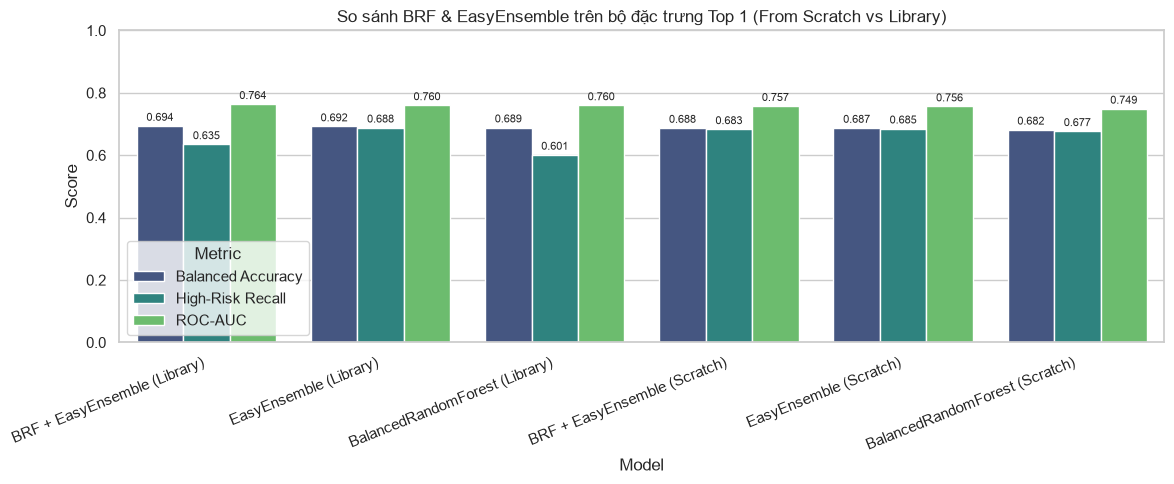

In [19]:
rows = []
for name in trained_models:
    y_pred = predictions_dict[name]
    y_prob = probabilities_dict[name]
    report = classification_report(
        y_test, y_pred, target_names=["low_risk", "high_risk"], output_dict=True, zero_division=0
    )
    rows.append(
        {
            "Model": name,
            "Source": model_sources[name],
            "Balanced Accuracy": balanced_accuracy_score(y_test, y_pred),
            "High-Risk Recall": report["high_risk"]["recall"],
            "High-Risk Precision": report["high_risk"]["precision"],
            "High-Risk F1": report["high_risk"]["f1-score"],
            "ROC-AUC": roc_auc_score(y_test, y_prob),
            "Overall Accuracy": accuracy_score(y_test, y_pred),
            "Train Time (s)": train_times[name],
        }
    )

comparison_df = (
    pd.DataFrame(rows)
    .sort_values(by=["Balanced Accuracy", "High-Risk Recall"], ascending=False)
    .reset_index(drop=True)
)

print("=" * 100)
print("BẢNG SO SÁNH: TOP-1 FE + BALANCED RANDOM FOREST & EASYENSEMBLE (FROM SCRATCH VS LIBRARY)")
print("=" * 100)
display(comparison_df.round(4))

# Chọn mô hình tốt nhất làm thước đo cuối
best_row = comparison_df.iloc[0]
best_model_name = best_row["Model"]
best_y_pred = predictions_dict[best_model_name]

print("\n" + "*" * 100)
print(f"THƯỚC ĐO CUỐI ĐƯỢC CHỌN (FINAL BENCHMARK): {best_model_name} [{best_row['Source']}]")
print(
    f"  -> Balanced Accuracy: {best_row['Balanced Accuracy']:.4f} | "
    f"High-Risk Recall: {best_row['High-Risk Recall']:.4f} | "
    f"High-Risk F1: {best_row['High-Risk F1']:.4f} | "
    f"ROC-AUC: {best_row['ROC-AUC']:.4f}"
)
print("*" * 100)

# Biểu đồ so sánh trực quan
plot_df = comparison_df.melt(
    id_vars=["Model", "Source"],
    value_vars=["Balanced Accuracy", "High-Risk Recall", "ROC-AUC"],
    var_name="Metric",
    value_name="Score",
)
plt.figure(figsize=(12, 5))
ax = sns.barplot(data=plot_df, x="Model", y="Score", hue="Metric", palette="viridis")
ax.set_title("So sánh BRF & EasyEnsemble trên bộ đặc trưng Top 1 (From Scratch vs Library)")
ax.set_ylim(0, 1.0)
plt.xticks(rotation=22, ha="right")
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", fontsize=8, padding=2)
plt.tight_layout()
plt.show()

=== CLASSIFICATION REPORT (FINAL BENCHMARK: BRF + EasyEnsemble (Library)) ===

               precision    recall  f1-score   support

 low_risk (0)       0.96      0.75      0.84     70672
high_risk (1)       0.18      0.64      0.29      6206

     accuracy                           0.74     76878
    macro avg       0.57      0.69      0.56     76878
 weighted avg       0.90      0.74      0.80     76878



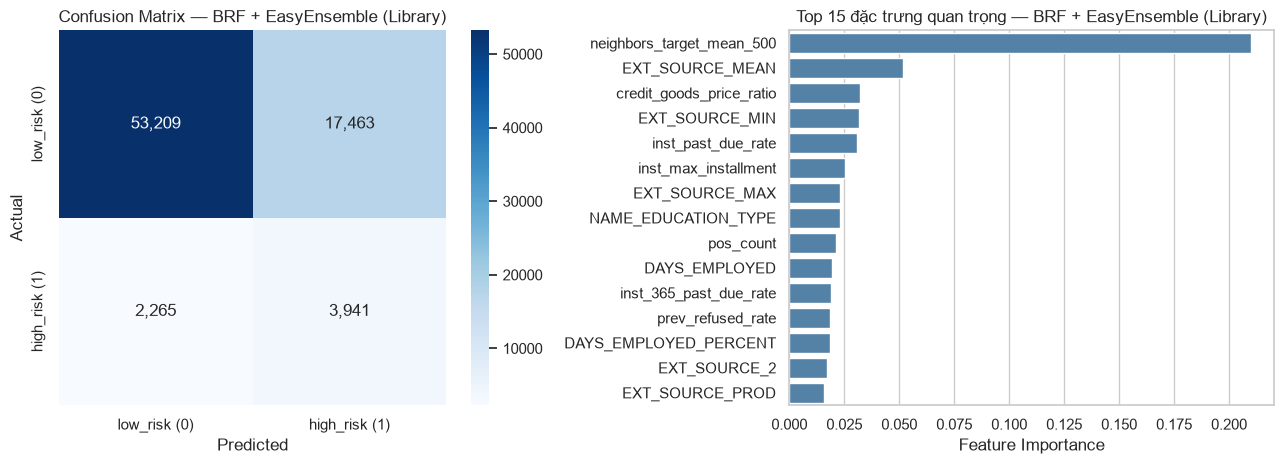

In [20]:
# Đánh giá chi tiết mô hình chiến thắng (Final Benchmark): Classification Report, Confusion Matrix & Top 15 Features
print(f"=== CLASSIFICATION REPORT (FINAL BENCHMARK: {best_model_name}) ===\n")
print(classification_report(y_test, best_y_pred, target_names=["low_risk (0)", "high_risk (1)"], zero_division=0))

cm = confusion_matrix(y_test, best_y_pred, labels=[0, 1])
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

# 1. Confusion Matrix
sns.heatmap(
    cm,
    annot=True,
    fmt=",d",
    cmap="Blues",
    xticklabels=["low_risk (0)", "high_risk (1)"],
    yticklabels=["low_risk (0)", "high_risk (1)"],
    ax=axes[0],
)
axes[0].set_title(f"Confusion Matrix — {best_model_name}")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

# 2. Top 15 đặc trưng quan trọng nhất của mô hình chiến thắng
importances = np.asarray(feature_imp_dict[best_model_name])
top_idx = np.argsort(importances)[::-1][:15]
top_features_df = pd.DataFrame(
    {"Feature": [feature_names[i] for i in top_idx], "Importance": importances[top_idx]}
)
sns.barplot(data=top_features_df, x="Importance", y="Feature", color="steelblue", ax=axes[1])
axes[1].set_title(f"Top 15 đặc trưng quan trọng — {best_model_name}")
axes[1].set_xlabel("Feature Importance")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

## 5. Conclusion & Future Work

### Kết luận
1. **Áp dụng trọn vẹn Tiền xử lý & Feature Engineering từ giải pháp Top 1 Kaggle:** Kết hợp đầy đủ thông tin từ bảng chính + 5 bảng lịch sử tín dụng (`bureau`, `previous_application`, `installments_payments`, `POS_CASH_balance`, `credit_card_balance`), cắt lát theo thời gian, đặc trưng láng giềng `neighbors_target_mean_500` chống rò rỉ dữ liệu, Label+Frequency Encoding và chọn lọc đặc trưng bằng `Ridge`.
2. **Giữ nguyên phương pháp Balanced Random Forest kết hợp EasyEnsemble ở cả 2 cách:** Đối chiếu trực tiếp giữa **From Scratch (Pure NumPy)** và **Library (`imbalanced-learn`)** trên cùng bộ dữ liệu và cùng chuẩn đánh giá (**Balanced Accuracy**, **Confusion Matrix**, **Classification Report**).
3. **Thước đo cuối (Final Benchmark):** Notebook tự động chọn mô hình đạt hiệu năng cao nhất làm mốc chuẩn cuối cho bài toán.

### Hướng phát triển tiếp theo (Future Work)
1. **Mở rộng cắt lát thời gian (Time-weighted & Lag Features):** Bổ sung thêm trung bình có trọng số thời gian (Yang) và lag features cho 5 đơn vay gần nhất (Ryan) kết hợp bảng `bureau_balance.csv`.
2. **Tối ưu trọng số Soft Voting & Threshold Tuning:** Tối ưu trọng số kết hợp $w \cdot P_{\text{BRF}} + (1-w) \cdot P_{\text{EasyEnsemble}}$ và ngưỡng phân loại trên tập Validation (`StratifiedKFold`).
3. **Giải thích mô hình:** Tích hợp **SHAP** để phân tích tác động của từng đặc trưng Top 1 (`neighbors_target_mean_500`, `EXT_SOURCE_*`, `debt_credit_ratio_None`,...) lên từng hồ sơ vay.